# Homework 9


**Concepts covered:**

matplotlib, line charts, pie chart, histogram, scatterplot

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning against using generative AI:**

We recommend *in the strongest terms* against using generative AI in solving any homework assignment in this module. The goal of these assignments is for you to learn the fundamental concepts about programming: syntax, correctness, problem decomposition, and skepticism. While we know that generative AI can solve all of these problems, you will not be learning anything and will get confused as this module progresses.

While we encourage you to use AI to generate practice problems, you should try to solve these problems with the help of the sample problems, and examples on blackboard and experimentation.



**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.


## Shared Imports

Run the cell below to import modules that will be used through out
this homework notebook. Do not import any other modules.
In particular, other charting modules such as Seaborn are not allowed.

In [1]:
# shared imports
import math
import numpy as np
import matplotlib.pyplot as plt


**NOTE: Use the appropriate and optimal ranges for the axis values so that the visualizations are not too small.**


**This homework is partially autograded. The plots will be manually graded so please allow some time for you to get a full score.**

**Problem 1 (review)**

**Concept:** *NumPy arrays, math functions*

**Task:**

Write three functions that generate numerical arrays using NumPy.

Each function takes three parameters:

* **start** – the starting value of the array

* **stop** – the ending value of the array (not inclusive)

* **steps** – the increment between values in the array (the step size used by `np.arange`)

Use `np.arange(start, stop, steps)` to generate the base array of values. Then apply the requested NumPy math function to the entire array.

**Functions to Implement:**

1. `generate_sine_wave(start, stop, steps)`

* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the sine of each value using `np.sin`.
* Return the array of sine values.
2. `generate_logs(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Compute the natural logarithm of each value using `np.log`.
* Return the array of log values.
3. `generate_rounded(start, stop, steps)`
* Generate a NumPy array of values from `start` to `stop` using `np.arange`.
* Round each value using `np.round`.
* Return the rounded array.



In [2]:
# Your Solution
def generate_sine_wave(start, stop, steps):
    """
    Generate an array of values from start to stop (exclusive) with the given
    step size, and return the sine of each value.

    Parameters:
        start (float): first value of the range
        stop (float): end of the range (not included)
        steps (float): increment between consecutive values

    Returns:
        np.ndarray: sine of every value in the range
    """
    # build the base array of evenly spaced values
    values = np.arange(start, stop, steps)
    # apply sine element-wise to the whole array
    return np.sin(values)


def generate_logs(start, stop, steps):
    """
    Generate an array of values from start to stop (exclusive) with the given
    step size, and return the natural logarithm of each value.

    Parameters:
        start (float): first value of the range
        stop (float): end of the range (not included)
        steps (float): increment between consecutive values

    Returns:
        np.ndarray: natural log of every value in the range
    """
    # build the base array of evenly spaced values
    values = np.arange(start, stop, steps)
    # apply the natural log element-wise to the whole array
    return np.log(values)


def generate_rounded(start, stop, steps):
    """
    Generate an array of values from start to stop (exclusive) with the given
    step size, and return each value rounded to the nearest integer.

    Parameters:
        start (float): first value of the range
        stop (float): end of the range (not included)
        steps (float): increment between consecutive values

    Returns:
        np.ndarray: rounded value of every value in the range
    """
    # build the base array of evenly spaced values
    values = np.arange(start, stop, steps)
    # round every element of the array
    return np.round(values)


# quick checks of each function
print(generate_sine_wave(0, 3, 1))
print(generate_logs(1, 4, 1))
print(generate_rounded(0, 2, 0.4))

[0.         0.84147098 0.90929743]
[0.         0.69314718 1.09861229]
[0. 0. 1. 1. 2.]


**Problem 2 (review)**

**Concept:** *reading CSV file, create an np.array of numbers*

**Task:**

Write a function `read_csv_to_dict(filename)` that reads a CSV file and stores the data in a dictionary.

Your function should:
1. Open the CSV file.
2. Read the first row to obtain column headers.
3. Store each column of data as a NumPy array.
4. Use the column names as keys in the dictionary.
5. Return the dictionary.

Each key should correspond to one column in the CSV file.

Example structure:

```
{
   "open": np.array([...]),
   "close": np.array([...]),
   "volume": np.array([...])
}
```


In [3]:
#Your Solution

def read_csv_to_dict(filename):
    """
    Read a CSV file and return its contents as a dictionary of NumPy arrays.

    The first row of the file is treated as the column headers. Each header
    becomes a key, and the values under it are stored as a NumPy array.
    Columns whose values are all numeric are stored as float arrays;
    any other column (e.g. text labels) is stored as an array of strings.

    Parameters:
        filename (str): path to the CSV file

    Returns:
        dict: {column_name: np.ndarray of that column's values}
    """
    # open the file and read all lines
    with open(filename, "r") as file:
        lines = file.readlines()

    # first row holds the column headers; strip whitespace/quotes from each
    headers = [h.strip().strip('"') for h in lines[0].strip().split(",")]

    # one empty list per column to collect values
    columns = {header: [] for header in headers}

    # loop over every data row after the header
    for line in lines[1:]:
        line = line.strip()
        # skip blank lines (e.g. a trailing newline at the end of the file)
        if line == "":
            continue
        values = [v.strip().strip('"') for v in line.split(",")]
        # pair each value with its column header and store it
        for header, value in zip(headers, values):
            columns[header].append(value)

    # convert each column list into a NumPy array
    data = {}
    for header, values in columns.items():
        try:
            # numeric column -> float array
            data[header] = np.array(values, dtype=float)
        except ValueError:
            # non-numeric column (e.g. labels) -> string array
            data[header] = np.array(values)
    return data



**Problem 3**

**Concepts:** *matplotlib, plt line*

**Task:**

Use NumPy and Matplotlib to generate and plot sine and cosine waves.

Complete the following steps:

1. Create a range of values from **0 to 20** using `np.arange`.
2. Compute:
* the sine wave
* the cosine wave

Create four plots:
1. Plot the **sine wave** by itself.
2. Plot the **cosine wave** by itself.
3. Plot **both waves together on the same chart** with a legend.
4. Compute the **ratio of sine to cosine** and plot it.

Each chart should include a **title**, and the combined chart should include a **legend**.


**Plot 1:**

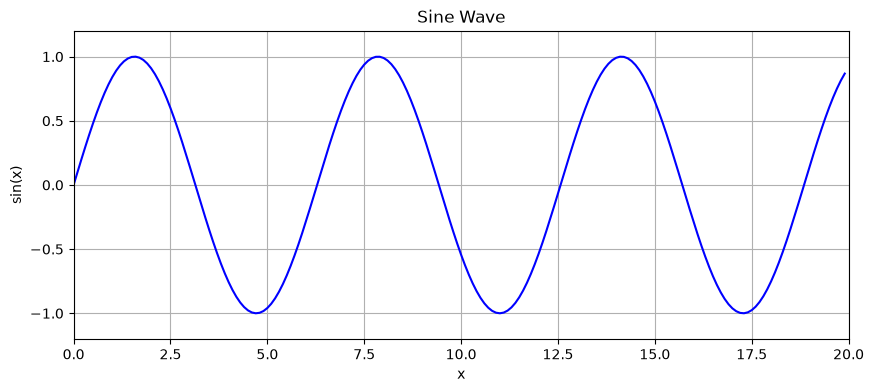

In [5]:
#Your Solution

# shared data for all four plots: values from 0 to 20 in small steps
x = np.arange(0, 20, 0.1)
sine = np.sin(x)      # sine wave
cosine = np.cos(x)    # cosine wave

# plot the sine wave on its own
plt.figure(figsize=(10, 4))
plt.plot(x, sine, color="blue")
plt.title("Sine Wave")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.xlim(0, 20)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.show()

**Plot 2:**

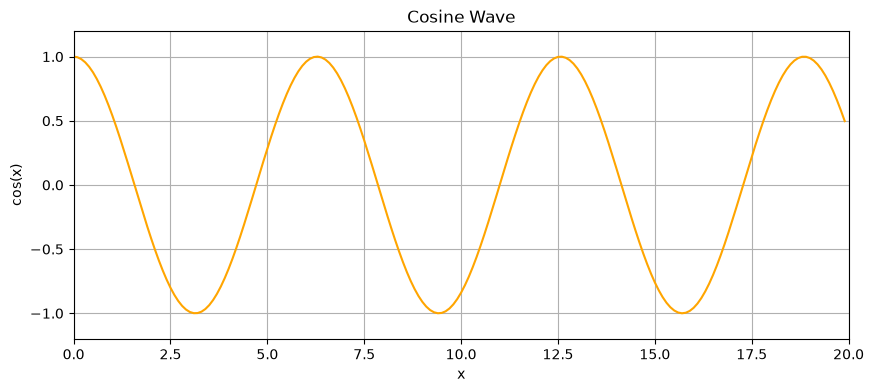

In [6]:
#Your Solution
# plot the cosine wave on its own
plt.figure(figsize=(10, 4))
plt.plot(x, cosine, color="orange")
plt.title("Cosine Wave")
plt.xlabel("x")
plt.ylabel("cos(x)")
plt.xlim(0, 20)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.show()

**Plot 3:**

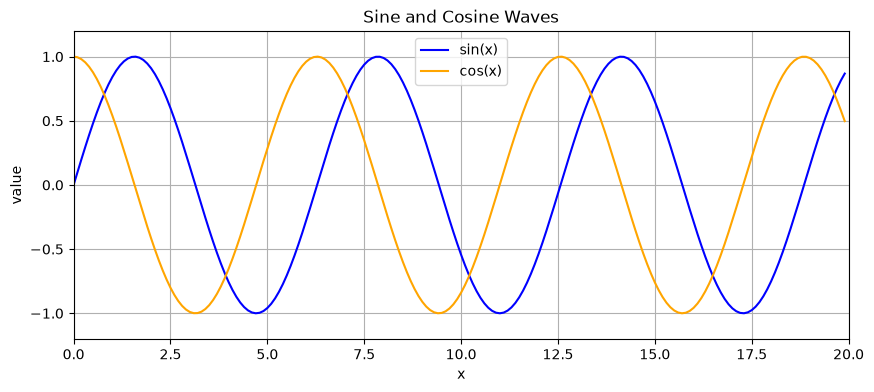

In [7]:
#Your Solution
# plot both waves on the same chart with a legend
plt.figure(figsize=(10, 4))
plt.plot(x, sine, label="sin(x)", color="blue")
plt.plot(x, cosine, label="cos(x)", color="orange")
plt.title("Sine and Cosine Waves")
plt.xlabel("x")
plt.ylabel("value")
plt.xlim(0, 20)
plt.ylim(-1.2, 1.2)
plt.legend()
plt.grid(True)
plt.show()

**Plot 4:**

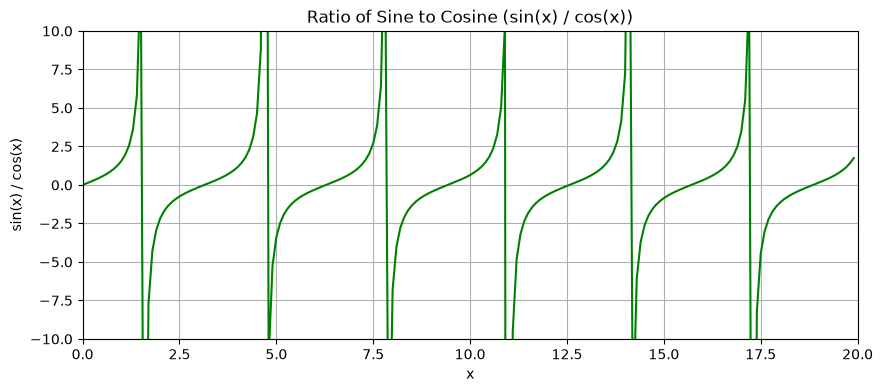

In [8]:
#Your Solution
# ratio of sine to cosine (this is tan(x)); it shoots toward +/- infinity
# wherever cos(x) is near 0, so the y-axis is limited to keep the shape readable
ratio = sine / cosine
plt.figure(figsize=(10, 4))
plt.plot(x, ratio, color="green")
plt.title("Ratio of Sine to Cosine (sin(x) / cos(x))")
plt.xlabel("x")
plt.ylabel("sin(x) / cos(x)")
plt.xlim(0, 20)
plt.ylim(-10, 10)
plt.grid(True)
plt.show()

**Problem 4**

**Concepts:** *matplotlib, bar chart*

**Task:**

Use the provided lists representing fruit consumption over several days.

Create the following visualizations:

1. A **stacked bar chart** showing strawberry and banana consumption.
2. Two **separate bar charts using subplots**:
* One chart for strawberries (red)
* One chart for bananas (yellow)

Each chart should include:
* a title
* a legend

In [9]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]


**Plot 1: Stacked Bar Chart**

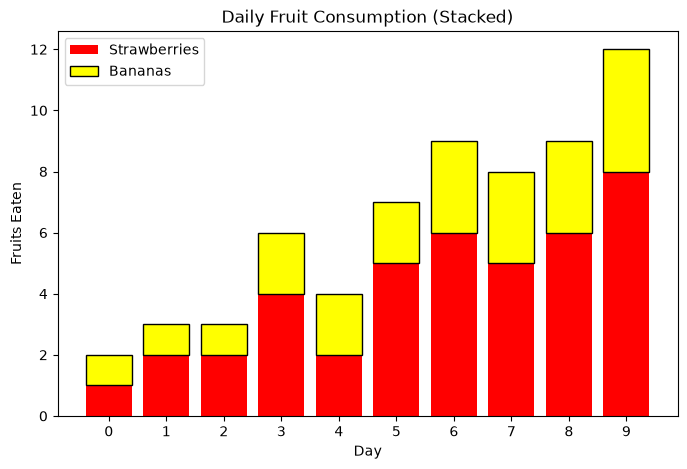

In [10]:
#Your Solution
# stacked bars: bananas are drawn on top of strawberries using bottom=
plt.figure(figsize=(8, 5))
plt.bar(days, strawberries, color="red", label="Strawberries")
plt.bar(days, bananas, bottom=strawberries, color="yellow",
        edgecolor="black", label="Bananas")
plt.title("Daily Fruit Consumption (Stacked)")
plt.xlabel("Day")
plt.ylabel("Fruits Eaten")
plt.xticks(days)
plt.legend()
plt.show()

**Plot 2: Separate Bar Chart**

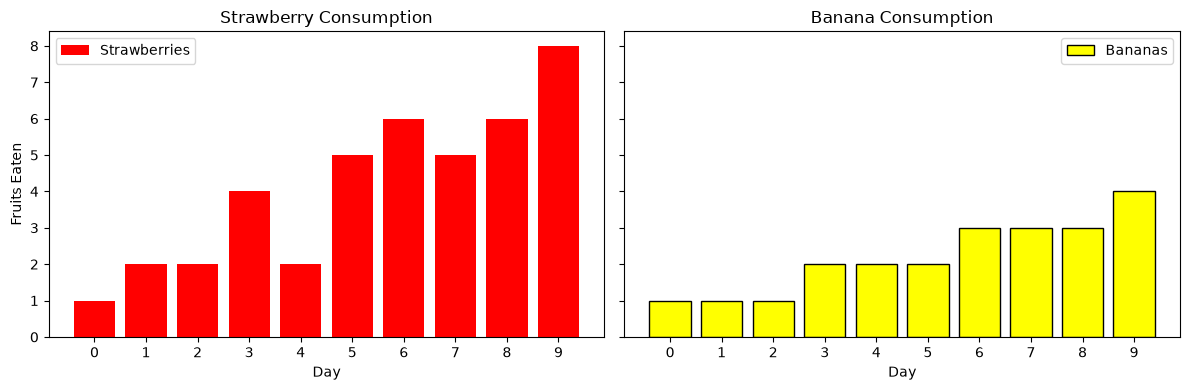

In [11]:
#Your Solution
# two side-by-side subplots that share the same y-axis scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# left subplot: strawberries in red
ax1.bar(days, strawberries, color="red", label="Strawberries")
ax1.set_title("Strawberry Consumption")
ax1.set_xlabel("Day")
ax1.set_ylabel("Fruits Eaten")
ax1.set_xticks(list(days))
ax1.legend()

# right subplot: bananas in yellow
ax2.bar(days, bananas, color="yellow", edgecolor="black", label="Bananas")
ax2.set_title("Banana Consumption")
ax2.set_xlabel("Day")
ax2.set_xticks(list(days))
ax2.legend()

plt.tight_layout()
plt.show()

**Problem 5**

**Concepts:** *matplotlib, bar chart*

**Task:**

Using the same fruit consumption data from Problem 4, create a **grouped bar chart**.

Your chart should:
1. Display strawberries (red) and bananas (yellow) side-by-side for each day.
2. Use a bar width to offset the second set of bars.
3. Label the x-axis with the day numbers.
4. Include:
    * axis labels
    * a title
    * a legend

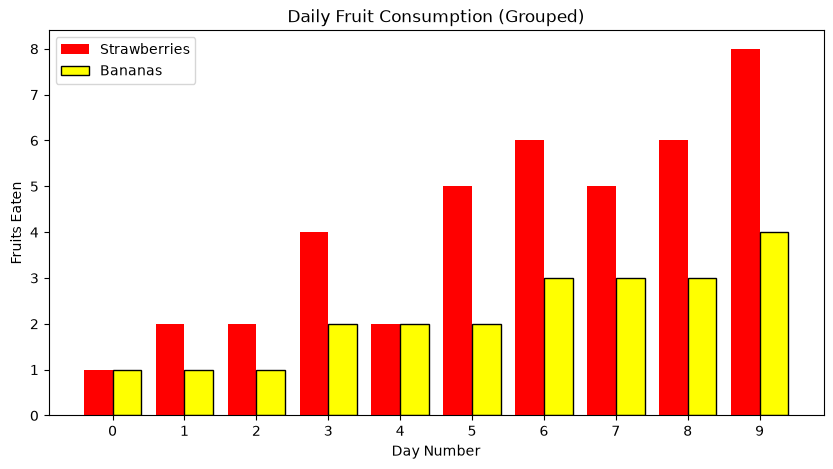

In [13]:
# STARTER CODE; DO NOT CHANGE
days = range(10)
strawberries = [1, 2, 2, 4, 2, 5, 6, 5, 6, 8]
bananas = [1, 1, 1, 2, 2, 2, 3, 3, 3, 4]

#Your Solution
bar_width = 0.4                   # width of each bar
positions = np.arange(len(days))  # base x position for each day

plt.figure(figsize=(10, 5))
# strawberries shifted half a bar to the left
plt.bar(positions - bar_width / 2, strawberries, width=bar_width,
        color="red", label="Strawberries")
# bananas shifted half a bar to the right so the pair sits side by side
plt.bar(positions + bar_width / 2, bananas, width=bar_width,
        color="yellow", edgecolor="black", label="Bananas")

# label the x-axis ticks with the day numbers
plt.xticks(positions, list(days))
plt.xlabel("Day Number")
plt.ylabel("Fruits Eaten")
plt.title("Daily Fruit Consumption (Grouped)")
plt.legend()
plt.show()



**Problem 6**

**Concepts:** *matplotlib, scatter plot*


**Task:**

Create a scatter plot that displays the points of a **unit circle**.

Steps:

1. Generate `x` values between **0 and 1**.
2. Compute the corresponding `y` values using the circle equation:

$$y = sqrt(1 − x²)$$

3. Reflect the points across all four quadrants so that the full circle is drawn.
4. Plot the points using `plt.scatter`.

Set the figure size to **(5,5)** so the circle appears correctly proportioned.

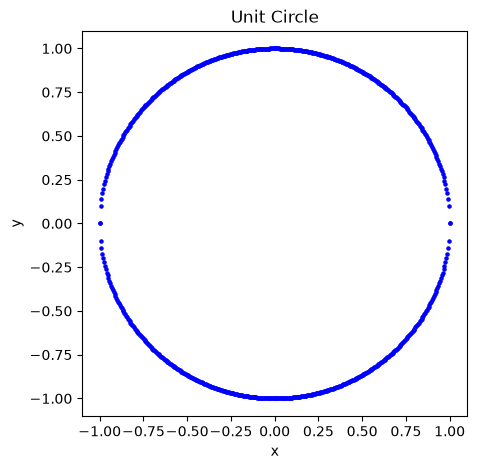

In [14]:
#Your Solution
# x values from 0 to 1 (inclusive) for the first quadrant
x = np.linspace(0, 1, 200)
# circle equation: y = sqrt(1 - x^2)
y = np.sqrt(1 - x ** 2)

plt.figure(figsize=(5, 5))
# reflect the quarter arc into all four quadrants
plt.scatter(x, y, s=5, color="blue")     # quadrant I   ( x,  y)
plt.scatter(-x, y, s=5, color="blue")    # quadrant II  (-x,  y)
plt.scatter(-x, -y, s=5, color="blue")   # quadrant III (-x, -y)
plt.scatter(x, -y, s=5, color="blue")    # quadrant IV  ( x, -y)

plt.title("Unit Circle")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.gca().set_aspect("equal")  # keep the circle round
plt.show()

**Problem 7**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot using the provided `x_data` and `y_data`.

Plot the data **four different ways on the same chart**:
1. Original values `(x, y)`
2. Horizontal reflection `(-x, y)`
3. Vertical reflection `(x, -y)`
4. Reflection across both axes `(-x, -y)`

Add:
* a legend
* a chart title

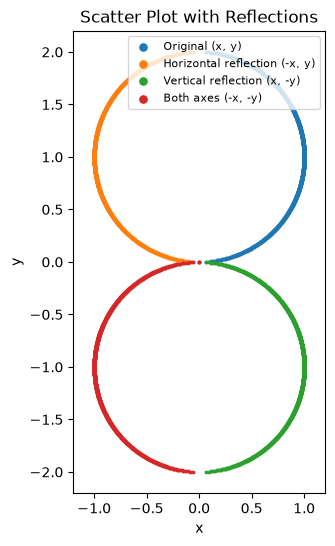

In [15]:
# STARTER CODE; DO NOT CHANGE

y_data = [i / 500 for i in range(1000)]
x_data = [math.sqrt(1 - (y - 1)**2) for y in y_data]


#Your Solution

# convert to arrays so the values can be negated in one step
x_arr = np.array(x_data)
y_arr = np.array(y_data)

plt.figure(figsize=(6, 6))
# plot the original points and their three reflections
plt.scatter(x_arr, y_arr, s=3, label="Original (x, y)")
plt.scatter(-x_arr, y_arr, s=3, label="Horizontal reflection (-x, y)")
plt.scatter(x_arr, -y_arr, s=3, label="Vertical reflection (x, -y)")
plt.scatter(-x_arr, -y_arr, s=3, label="Both axes (-x, -y)")

plt.title("Scatter Plot with Reflections")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(-1.2, 1.2)
plt.ylim(-2.2, 2.2)
plt.gca().set_aspect("equal")
plt.legend(loc="upper right", fontsize=8, markerscale=3)
plt.show()



**Problem 8**

**Concepts:** *matplotlib, scatter plot*

**Task:**

Create a scatter plot that produces a **spiral or tornado-like pattern**.

Steps:
1. Generate a list of radius values that gradually increase so the points move farther away from the center over time.
2. Use a sequence of angle values so that each point rotates a little more than the previous one.
3. Compute the x-coordinates by multiplying each radius value by the cosine of its angle.
4. Compute the y-coordinates by multiplying each radius value by the sine of its angle.
5. Use plt.scatter() to plot the (x, y) points.
6. Add a title to the chart.



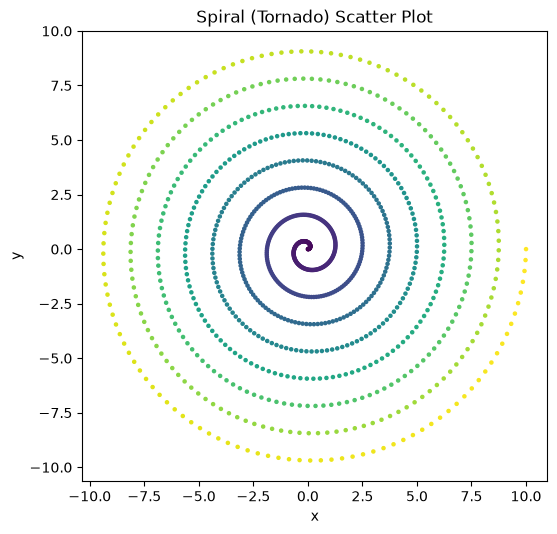

In [16]:
#Your Solution
num_points = 1000
# radius grows steadily so points move farther from the center
radius = np.linspace(0, 10, num_points)
# each point rotates a little more than the one before (8 full turns)
angle = np.linspace(0, 8 * 2 * np.pi, num_points)

# polar to cartesian conversion
x = radius * np.cos(angle)
y = radius * np.sin(angle)

plt.figure(figsize=(6, 6))
# color each point by its position in the sequence to show the spiral path
plt.scatter(x, y, c=angle, cmap="viridis", s=5)
plt.title("Spiral (Tornado) Scatter Plot")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.show()



**Problem 9**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Using the helper function `read_csv_to_dict`, read a dataset stored in `p9_data.csv` containing two numerical variables.

The dataset contains the following columns:

* `dataset` (string label)

* `x` (numerical variable)

* `y` (numerical variable)

Create a scatter plot using the **x** and **y** values for the dataset.

Your plot should include:
* x-axis label
* y-axis label
* title

The goal is to visualize how the two variables relate to each other.

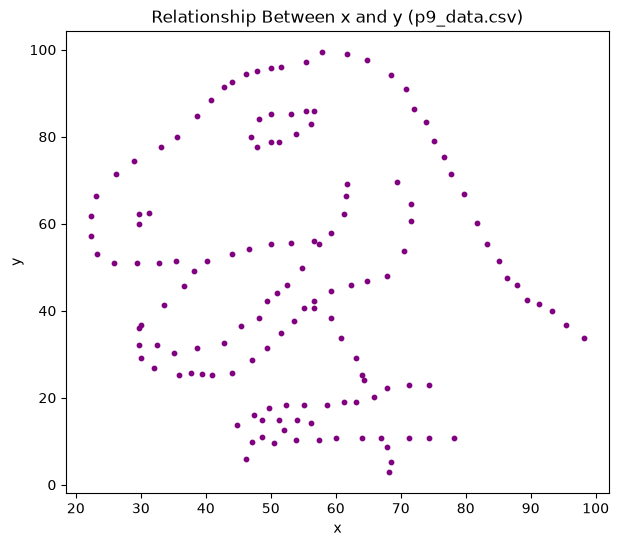

In [17]:
#Your Solution
# read the dataset into a dictionary of arrays
p9 = read_csv_to_dict("p9_data.csv")

# make sure the x and y columns are numeric
x_values = np.array(p9["x"], dtype=float)
y_values = np.array(p9["y"], dtype=float)

plt.figure(figsize=(7, 6))
plt.scatter(x_values, y_values, s=10, color="purple")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Relationship Between x and y (p9_data.csv)")
plt.show()

**Problem 10**

**Concepts:** *reading CSV file, line graph*

**Task:**

Write a function:

`create_line_graph(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Verify the specified column exists.
3. Convert the column values to floats.
4. Plot the values as a **line graph**.

Your graph should include:
* a title
* x-axis labeled **Day Number**
* y-axis labeled with the column name

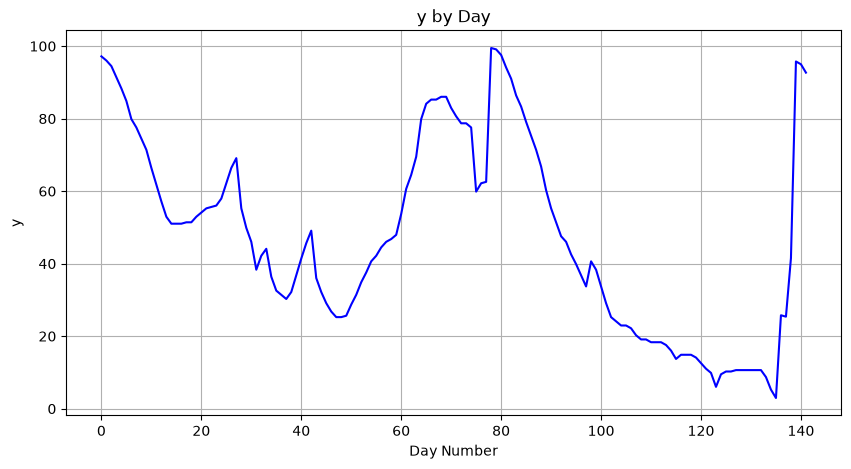

In [18]:
#Your Solution

def create_line_graph(filename, column_name):
    """
    Read a CSV file and plot one of its columns as a line graph.

    The x-axis is the day number (row index) and the y-axis is the value
    in the requested column.

    Parameters:
        filename (str): path to the CSV file
        column_name (str): name of the column to plot

    Returns:
        None. Displays the line graph, or prints a message if the column
        does not exist.
    """
    # read the CSV into a dictionary of arrays
    data = read_csv_to_dict(filename)

    # verify the requested column exists before plotting
    if column_name not in data:
        print(f"Column '{column_name}' not found in {filename}.")
        return

    # convert the column values to floats
    values = np.array(data[column_name], dtype=float)
    # day numbers 0, 1, 2, ... one per row
    day_numbers = np.arange(len(values))

    plt.figure(figsize=(10, 5))
    plt.plot(day_numbers, values, color="blue")
    plt.title(f"{column_name} by Day")
    plt.xlabel("Day Number")
    plt.ylabel(column_name)
    plt.grid(True)
    plt.show()


# example call using the dataset from Problem 9
create_line_graph("p9_data.csv", "y")


**Problem 11**

**Concepts:** *reading CSV file, histogram*

**Task:**

Write a function:

`create_histogram(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Create a histogram of the data.

Requirements:
* Use **at least 10 bins**.
* Add a title showing the column name.

The histogram should display the distribution of values in the selected column.

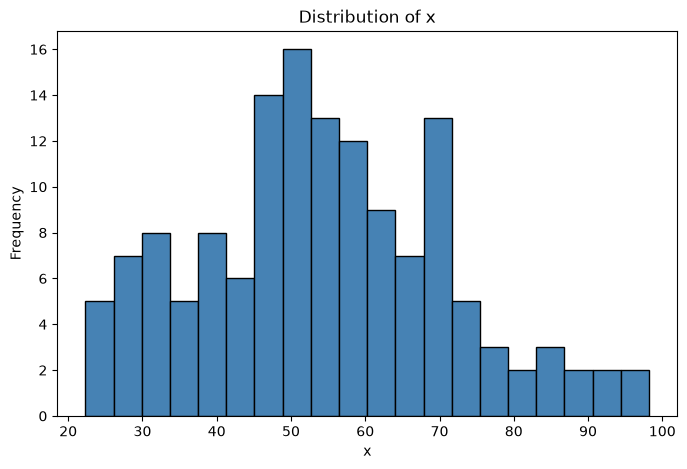

In [19]:
#Your Solution
def create_histogram(filename, column_name):
    """
    Read a CSV file and plot a histogram of one of its columns.

    Parameters:
        filename (str): path to the CSV file
        column_name (str): name of the column to plot

    Returns:
        None. Displays the histogram, or prints a message if the column
        does not exist.
    """
    # read the CSV into a dictionary of arrays
    data = read_csv_to_dict(filename)

    # stop early if the column is missing
    if column_name not in data:
        print(f"Column '{column_name}' not found in {filename}.")
        return

    # convert the column to numeric values
    values = np.array(data[column_name], dtype=float)

    plt.figure(figsize=(8, 5))
    # 20 bins (at least 10 required) to show the distribution
    plt.hist(values, bins=20, color="steelblue", edgecolor="black")
    plt.title(f"Distribution of {column_name}")
    plt.xlabel(column_name)
    plt.ylabel("Frequency")
    plt.show()


# example call using the dataset from Problem 9
create_histogram("p9_data.csv", "x")

**Problem 12**

**Concepts:** *reading CSV file, pie chart*

**Task:**

Write a function:

`create_pie_chart(filename, column_name)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Convert the selected column to numeric values.
3. Compute the **mean value** of the column.
4. Determine:
* the percentage of values **greater than the mean**
* the percentage **less than or equal to the mean**

Create a pie chart displaying these two proportions.

Include:
* labels
* percentages
* chart title

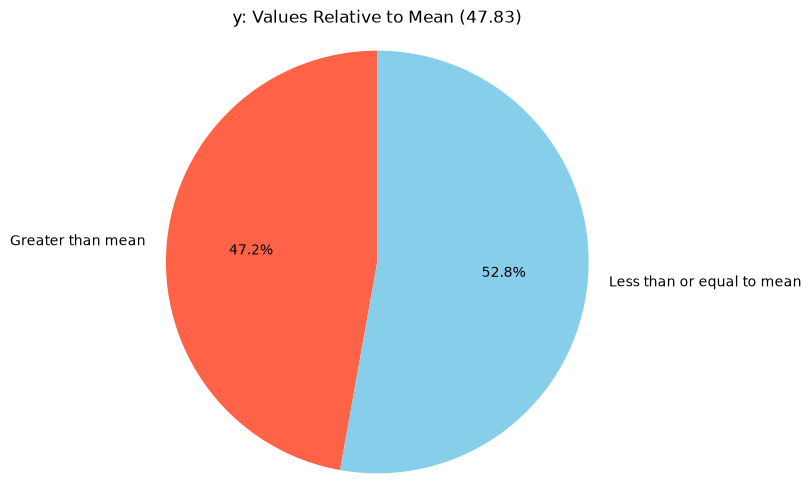

In [20]:
#Your Solution
def create_pie_chart(filename, column_name):
    """
    Read a CSV file and show a pie chart comparing the share of values in a
    column that are greater than the column's mean versus less than or equal
    to the mean.

    Parameters:
        filename (str): path to the CSV file
        column_name (str): name of the column to analyze

    Returns:
        None. Displays the pie chart, or prints a message if the column
        does not exist.
    """
    # read the CSV into a dictionary of arrays
    data = read_csv_to_dict(filename)

    # stop early if the column is missing
    if column_name not in data:
        print(f"Column '{column_name}' not found in {filename}.")
        return

    # convert the column to numeric values
    values = np.array(data[column_name], dtype=float)

    # mean of the column
    mean_value = np.mean(values)

    # count values above the mean and at-or-below the mean
    above = np.sum(values > mean_value)
    at_or_below = np.sum(values <= mean_value)

    # convert counts to percentages of the total
    total = len(values)
    pct_above = above / total * 100
    pct_at_or_below = at_or_below / total * 100

    plt.figure(figsize=(6, 6))
    # autopct prints each slice's percentage on the chart
    plt.pie([pct_above, pct_at_or_below],
            labels=["Greater than mean", "Less than or equal to mean"],
            colors=["tomato", "skyblue"],
            autopct="%1.1f%%",
            startangle=90)
    plt.title(f"{column_name}: Values Relative to Mean ({mean_value:.2f})")
    plt.axis("equal")  # keep the pie circular
    plt.show()


# example call using the dataset from Problem 9
create_pie_chart("p9_data.csv", "y")

**Problem 13**

**Concepts:** *reading CSV file, scatter plot*

**Task:**

Write a function:

`create_scatter_plot(filename, x_column, y_column)`

Your function should:
1. Read the CSV file using `read_csv_to_dict`.
2. Extract the specified columns.
3. Convert the values to floats.
4. Create a scatter plot showing the relationship between the two variables.

Include:
* x-axis label
* y-axis label
* title

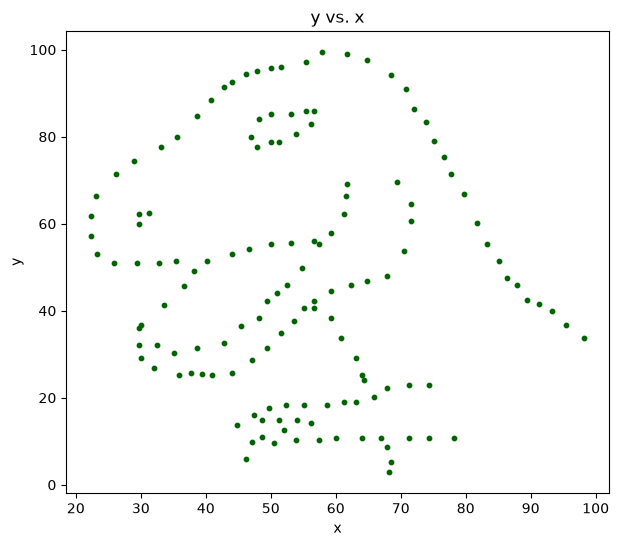

In [21]:
#Your Solution
def create_scatter_plot(filename, x_column, y_column):
    """
    Read a CSV file and create a scatter plot of two of its columns.

    Parameters:
        filename (str): path to the CSV file
        x_column (str): column to use for the x-axis
        y_column (str): column to use for the y-axis

    Returns:
        None. Displays the scatter plot, or prints a message if either
        column does not exist.
    """
    # read the CSV into a dictionary of arrays
    data = read_csv_to_dict(filename)

    # check both columns exist before plotting
    for column in (x_column, y_column):
        if column not in data:
            print(f"Column '{column}' not found in {filename}.")
            return

    # extract the two columns and convert them to floats
    x_values = np.array(data[x_column], dtype=float)
    y_values = np.array(data[y_column], dtype=float)

    plt.figure(figsize=(7, 6))
    plt.scatter(x_values, y_values, s=10, color="darkgreen")
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.title(f"{y_column} vs. {x_column}")
    plt.show()


# example call using the dataset from Problem 9
create_scatter_plot("p9_data.csv", "x", "y")